# Fine-tune Qwen2.5-VL for OCR with QLoRA (Colab)

End-to-end, runs on a **free Colab T4** in ~20 minutes with the 3B model. Switch to 7B on an L4/A100.

What this notebook does,

1. Load an OCR dataset (`Teklia/IAM-line`: handwritten text lines, `image` + `text`), or your own `CSV(image_path, text)`
2. Load `Qwen2.5-VL-Instruct` in 4-bit (QLoRA) and cap image resolution so token counts stay same
3. **Measure a baseline** (CER / WER) before touching anything
4. Build chat-format samples, mask the loss so the model only learns the answer tokens
5. Attach LoRA adapters to the language model only (vision tower frozen), train
6. Re-measure CER / WER on the same held-out samples, look at before/after examples
7. Save the adapter; merge it for serving

> Runtime → Change runtime type → **T4 GPU** (free) before running.

In [1]:
# 1. Install (pinned loosely; Qwen2.5-VL needs transformers >= 4.49)
%pip install -q "transformers>=4.49,<5" "peft>=0.13" "bitsandbytes>=0.44" "accelerate>=0.34" \
    "datasets>=2.20" "jiwer>=3.0" "pillow" "torchvision"
import torch, transformers, peft, bitsandbytes
print("torch", torch.__version__, "| transformers", transformers.__version__, "| peft", peft.__version__)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none")
print("bf16 supported:", torch.cuda.is_bf16_supported() if torch.cuda.is_available() else False)

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
torch 2.14.1+cu130 | transformers 4.57.6 | peft 0.21.2
GPU: Tesla T4
bf16 supported: True


## 2. Configuration

One place to change everything. On the H100 we should set `LOAD_IN_4BIT=False`, `MODEL_ID` to 7B, `BATCH_SIZE=8`, `MAX_STEPS=-1` with `NUM_EPOCHS=2`.

In [2]:
MODEL_ID       = "Qwen/Qwen2.5-VL-3B-Instruct"   # "Qwen/Qwen2.5-VL-7B-Instruct" on L4/A100
DATASET_ID     = "Teklia/IAM-line"
TRAIN_SAMPLES  = 1500      # subsample for Colab speed; full set is ~6.5k
EVAL_SAMPLES   = 60        # held-out lines scored before and after
LOAD_IN_4BIT   = True      # QLoRA. False = plain LoRA in bf16 (needs ~16 GB for 7B)
MAX_PIXELS     = 512 * 28 * 28   # cap image tokens (28px patches, merged 2x2 -> 14px per token side)
MIN_PIXELS     = 64  * 28 * 28

LORA_R, LORA_ALPHA, LORA_DROPOUT = 16, 32, 0.05
LR             = 2e-4
BATCH_SIZE     = 2
GRAD_ACCUM     = 4         # effective batch 8, same as the H100 run
MAX_STEPS      = 100       # ~20 min on T4 with 3B. Set -1 and use NUM_EPOCHS for a full run
NUM_EPOCHS     = 1
OUTPUT_DIR     = "qwen25vl-ocr-lora"

PROMPT = "Read all the text in this image. Output only the text, exactly as written."

import torch
USE_BF16 = torch.cuda.is_bf16_supported()   # T4 = False -> fp16; A100/H100/L4 = True
DTYPE = torch.bfloat16 if USE_BF16 else torch.float16
print("compute dtype:", DTYPE)

compute dtype: torch.bfloat16


## 3. Data

### 3a. Hugging Face dataset

README.md: 0.00B [00:00, ?B/s]

data/train.parquet:   0%|          | 0.00/167M [00:00<?, ?B/s]

data/validation.parquet:   0%|          | 0.00/24.7M [00:00<?, ?B/s]

data/test.parquet:   0%|          | 0.00/73.6M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/6482 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/976 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/2915 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['image', 'text'],
        num_rows: 6482
    })
    validation: Dataset({
        features: ['image', 'text'],
        num_rows: 976
    })
    test: Dataset({
        features: ['image', 'text'],
        num_rows: 2915
    })
})
text: 'link together the various West German'


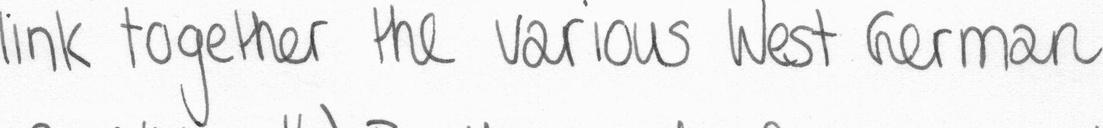

In [3]:
from datasets import load_dataset

ds = load_dataset(DATASET_ID)
print(ds)
train_ds = ds["train"].shuffle(seed=42).select(range(TRAIN_SAMPLES))
eval_ds  = ds["validation"].shuffle(seed=42).select(range(EVAL_SAMPLES))

ex = train_ds[0]
print("text:", repr(ex["text"]))
ex["image"]

### 3b. Your own data: `CSV(image_path, text)`

This mirrors the production pipeline: all images in one directory on the GPU box, a CSV with the file path and the ground-truth text. Uncomment to use it instead of 3a.

In [4]:
from datasets import Dataset, Image as HFImage
import pandas as pd

def dataset_from_csv(csv_path, image_dir=None, image_col="image_path", text_col="text"):
    df = pd.read_csv(csv_path)
    if image_dir:
        df[image_col] = df[image_col].apply(lambda p: f"{image_dir}/{p}")
    d = Dataset.from_pandas(df[[image_col, text_col]].rename(columns={image_col: "image", text_col: "text"}))
    return d.cast_column("image", HFImage())      # lazy-decodes from path when a row is accessed

# Example (uncomment):
# full = dataset_from_csv("/content/ocr_labels.csv", image_dir="/content/images")
# split = full.train_test_split(test_size=0.025, seed=42)   # ~10k of 400k held out, like the H100 run
# train_ds, eval_ds = split["train"], split["test"].select(range(EVAL_SAMPLES))

## 4. Model + processor (QLoRA: 4-bit NF4 base, bf16/fp16 compute)

In [5]:
from transformers import AutoProcessor, Qwen2_5_VLForConditionalGeneration, BitsAndBytesConfig

bnb = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_use_double_quant=True,
    bnb_4bit_compute_dtype=DTYPE,
) if LOAD_IN_4BIT else None

model = Qwen2_5_VLForConditionalGeneration.from_pretrained(
    MODEL_ID,
    quantization_config=bnb,
    torch_dtype=DTYPE,
    device_map="auto",
)
processor = AutoProcessor.from_pretrained(MODEL_ID, min_pixels=MIN_PIXELS, max_pixels=MAX_PIXELS)
processor.tokenizer.padding_side = "right"   # we mask by prefix length, so padding must be on the right

print(f"params: {sum(p.numel() for p in model.parameters())/1e9:.2f}B")
print(f"GPU mem after load: {torch.cuda.memory_allocated()/1e9:.2f} GB")

`torch_dtype` is deprecated! Use `dtype` instead!


config.json: 0.00B [00:00, ?B/s]

model.safetensors.index.json: 0.00B [00:00, ?B/s]

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

model-00001-of-00002.safetensors:   0%|          | 0.00/3.98G [00:00<?, ?B/s]

model-00002-of-00002.safetensors:   0%|          | 0.00/3.53G [00:00<?, ?B/s]

... (6 outputs left out)

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

chat_template.json: 0.00B [00:00, ?B/s]

params: 2.03B
GPU mem after load: 2.41 GB


## 5. Baseline: how good is the base model *before* fine-tuning?

Never skip this. The before/after delta is the number you quote in the interview.

In [6]:
import jiwer, re
from tqdm.auto import tqdm

def build_messages(answer=None):
    msgs = [{"role": "user", "content": [{"type": "image"}, {"type": "text", "text": PROMPT}]}]
    if answer is not None:
        msgs.append({"role": "assistant", "content": [{"type": "text", "text": answer}]})
    return msgs

@torch.no_grad()
def ocr(images, max_new_tokens=96):
    processor.tokenizer.padding_side = "left"          # generation needs left padding
    texts = [processor.apply_chat_template(build_messages(), tokenize=False, add_generation_prompt=True)] * len(images)
    inputs = processor(text=texts, images=images, padding=True, return_tensors="pt").to(model.device)
    out = model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False)
    processor.tokenizer.padding_side = "right"         # back to right for the training collator
    out = out[:, inputs["input_ids"].shape[1]:]
    return [t.strip() for t in processor.batch_decode(out, skip_special_tokens=True)]

def normalise(s):
    return re.sub(r"\s+", " ", s).strip()

def evaluate(dataset, batch=4, label=""):
    preds, refs = [], []
    model.eval()
    for i in tqdm(range(0, len(dataset), batch), desc=f"eval {label}"):
        rows = dataset[i:i+batch]
        preds += ocr(rows["image"])
        refs  += rows["text"]
    preds_n, refs_n = [normalise(p) for p in preds], [normalise(r) for r in refs]
    cer = jiwer.cer(refs_n, preds_n); wer = jiwer.wer(refs_n, preds_n)
    exact = sum(p == r for p, r in zip(preds_n, refs_n)) / len(refs_n)
    print(f"[{label}] CER={cer:.3f}  WER={wer:.3f}  exact-match={exact:.2%}  (n={len(refs_n)})")
    return {"cer": cer, "wer": wer, "exact": exact, "preds": preds, "refs": refs}

baseline = evaluate(eval_ds, label="baseline")
for p, r in list(zip(baseline["preds"], baseline["refs"]))[:5]:
    print(f"REF : {r}\nPRED: {p}\n")

eval baseline:   0%|          | 0/15 [00:00<?, ?it/s]

The following generation flags are not valid and may be ignored: ['temperature']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


[baseline] CER=0.066  WER=0.344  exact-match=18.33%  (n=60)
REF : 2massacree , 2yessir . " " If you 'll take a chance
PRED: Rmassacre, Expressir." "If you'll take a chance

REF : to mediaeval eyes . It was determined that 100,000
PRED: to medieval eyes. It was determined that 100,000

REF : A nice boy of course . But perhaps in the
PRED: A nice boy of course. But perhaps in thi

REF : not I , who started this conversation . "
PRED: not J, who started this conversation."

REF : in the Labour movement a more militant attitude
PRED: In the labour movement a more militant attitude



## 6. Training samples and loss masking

Each sample becomes a chat: `user: <image> + prompt` → `assistant: <ground-truth text>`.
Labels are `-100` (ignored) for every token up to and including the assistant header, and for padding, so the loss is computed **only on the answer**. That is the single most common mistake in VLM SFT: training on the prompt tokens too.

In [7]:
def collate(rows):
    images  = [r["image"].convert("RGB") for r in rows]
    full    = [processor.apply_chat_template(build_messages(r["text"]), tokenize=False) for r in rows]
    prompt  = [processor.apply_chat_template(build_messages(), tokenize=False, add_generation_prompt=True) for r in rows]

    batch   = processor(text=full,   images=images, padding=True, return_tensors="pt")
    p_batch = processor(text=prompt, images=images, padding=True, return_tensors="pt")
    prompt_len = p_batch["attention_mask"].sum(dim=1)        # right padding -> prefix length per row

    labels = batch["input_ids"].clone()
    labels[batch["attention_mask"] == 0] = -100
    for i, n in enumerate(prompt_len):
        labels[i, :n] = -100
    batch["labels"] = labels
    return batch

# sanity check: decode what the model is actually trained to produce
b = collate([train_ds[0], train_ds[1]])
for i in range(2):
    kept = b["labels"][i][b["labels"][i] != -100]
    print(f"sample {i}: seq_len={b['input_ids'].shape[1]}  answer_tokens={len(kept)}  ->", repr(processor.tokenizer.decode(kept)))

sample 0: seq_len=241  answer_tokens=8  -> 'link together the various West German<|im_end|>\n'
sample 1: seq_len=241  answer_tokens=6  -> 'of Gloucester .<|im_end|>\n'


## 7. LoRA on the language model only

- Target the attention + MLP projections of the LLM (`q/k/v/o_proj`, `gate/up/down_proj`)
- **Exclude the vision tower** (`visual.*`): its MLP uses the same layer names, and the regex below keeps it frozen. Unfreezing it is a later experiment, only if the domain images (phone video frames) are far from the pre-training distribution.
- `prepare_model_for_kbit_training` casts norms to fp32 and enables gradient checkpointing for QLoRA stability.

In [8]:
from peft import LoraConfig, get_peft_model, prepare_model_for_kbit_training

if LOAD_IN_4BIT:
    model = prepare_model_for_kbit_training(model, use_gradient_checkpointing=True)
else:
    model.gradient_checkpointing_enable()
model.enable_input_require_grads()

TRAIN_MERGER = False

lora_cfg = LoraConfig(
    r=LORA_R, lora_alpha=LORA_ALPHA, lora_dropout=LORA_DROPOUT, bias="none",
    task_type="CAUSAL_LM",
    target_modules=r"^(?!.*visual).*\.(q_proj|k_proj|v_proj|o_proj|gate_proj|up_proj|down_proj)$",
    modules_to_save=["merger"] if TRAIN_MERGER else None,
)

model = get_peft_model(model, lora_cfg)
model.print_trainable_parameters()

# prove the vision tower is untouched
n_vis = sum(1 for n, _ in model.named_modules() if "visual" in n and "lora" in n)
print("LoRA layers inside vision tower:", n_vis, "(must be 0)")

trainable params: 29,933,568 || all params: 3,784,556,544 || trainable%: 0.7909
LoRA layers inside vision tower: 0 (must be 0)


## 8. Train

In [9]:
from transformers import Trainer, TrainingArguments

args = TrainingArguments(
    output_dir=OUTPUT_DIR,
    per_device_train_batch_size=BATCH_SIZE,
    gradient_accumulation_steps=GRAD_ACCUM,
    learning_rate=LR,
    lr_scheduler_type="cosine",
    warmup_ratio=0.05,
    num_train_epochs=NUM_EPOCHS,
    max_steps=MAX_STEPS,
    logging_steps=10,
    save_strategy="no",
    bf16=USE_BF16, fp16=not USE_BF16,
    optim="paged_adamw_8bit" if LOAD_IN_4BIT else "adamw_torch",
    e
    gradient_checkpointing=True,
    gradient_checkpointing_kwargs={"use_reentrant": False},
    remove_unused_columns=False,     # keep raw image/text columns for the collator
    dataloader_num_workers=2,
    report_to="none",
)

trainer = Trainer(model=model, args=args, train_dataset=train_ds, data_collator=collate)
model.config.use_cache = False
trainer.train()
model.config.use_cache = True

Step,Training Loss
10,0.424300
20,0.184700
30,0.199200
40,0.237100
50,0.217000
60,0.206000
70,0.180600
80,0.225200
90,0.207400
100,0.201200


/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:957: UserWarning: inner dimension (3420) is not aligned for fast kernel with blocksize=64, falling back to slower implementation.
  warn(


## 9. After: same held-out samples, same metric

In [10]:
after = evaluate(eval_ds, label="fine-tuned")

print(f"\n{'':12s}{'CER':>8s}{'WER':>8s}{'exact':>8s}")
print(f"{'baseline':12s}{baseline['cer']:8.3f}{baseline['wer']:8.3f}{baseline['exact']:8.1%}")
print(f"{'fine-tuned':12s}{after['cer']:8.3f}{after['wer']:8.3f}{after['exact']:8.1%}")

print("\nExamples where the prediction changed:")
shown = 0
for ref, p0, p1 in zip(after["refs"], baseline["preds"], after["preds"]):
    if normalise(p0) != normalise(p1) and shown < 6:
        print(f"REF    : {ref}\nBEFORE : {p0}\nAFTER  : {p1}\n"); shown += 1

eval fine-tuned:   0%|          | 0/15 [00:00<?, ?it/s]

[fine-tuned] CER=0.033  WER=0.077  exact-match=65.00%  (n=60)

                 CER     WER   exact
baseline       0.066   0.344   18.3%
fine-tuned     0.033   0.077   65.0%

Examples where the prediction changed:
REF    : 2massacree , 2yessir . " " If you 'll take a chance
BEFORE : Rmassacre, Expressir." "If you'll take a chance
AFTER  : massacre ,ypressir . " " If you 'll take a chance

REF    : to mediaeval eyes . It was determined that 100,000
BEFORE : to medieval eyes. It was determined that 100,000
AFTER  : to medieval eyes . It was determined that 100,000

REF    : A nice boy of course . But perhaps in the
BEFORE : A nice boy of course. But perhaps in thi
AFTER  : nice boy of course . But perhaps in thi

REF    : not I , who started this conversation . "
BEFORE : not J, who started this conversation."
AFTER  : not J. , who started this conversation . "

REF    : in the Labour movement a more militant attitude
BEFORE : In the labour movement a more militant attitude
AFTER  : In t

## 10. Save the adapter, merge for serving

The adapter is a few tens of MB. For production you merge it into a bf16 copy of the base model (not the 4-bit one) and serve the merged weights with vLLM / TGI. Optionally quantise the merged model (AWQ/GPTQ) afterwards.

In [11]:
model.save_pretrained(f"{OUTPUT_DIR}/adapter")
processor.save_pretrained(f"{OUTPUT_DIR}/adapter")
!du -sh {OUTPUT_DIR}/adapter

# --- Merge (needs ~8 GB RAM for 3B, ~16 GB for 7B; run on CPU if GPU is tight) ---
# from peft import PeftModel
# base = Qwen2_5_VLForConditionalGeneration.from_pretrained(MODEL_ID, torch_dtype=torch.bfloat16, device_map="cpu")
# merged = PeftModel.from_pretrained(base, f"{OUTPUT_DIR}/adapter").merge_and_unload()
# merged.save_pretrained(f"{OUTPUT_DIR}/merged"); processor.save_pretrained(f"{OUTPUT_DIR}/merged")
# # serve: vllm serve ./qwen25vl-ocr-lora/merged --max-model-len 4096

130M	qwen25vl-ocr-lora/adapter


## 11. Inference with the adapter on a new image

REF : wish I could go with you ! " " Doctor
PRED: wish I could go with you ! " " Doctor


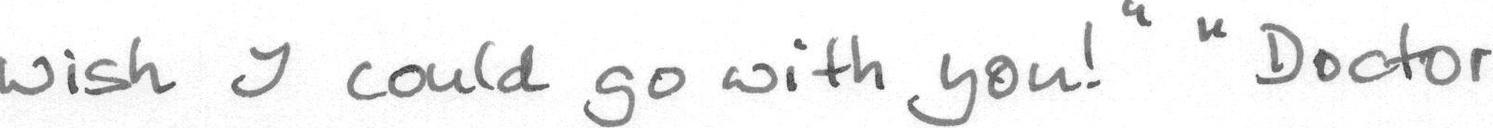

In [12]:
from PIL import Image
img = eval_ds[7]["image"]
print("REF :", eval_ds[7]["text"])
print("PRED:", ocr([img])[0])
img

## What changes between this notebook and the H100 production run

| | Colab (this notebook) | H100 80 GB, 400k images |
|---|---|---|
| Model | Qwen2.5-VL-3B, 4-bit (QLoRA) | Qwen2.5-VL-7B, bf16 (LoRA, no quantisation) |
| Precision | fp16 on T4 | bf16 |
| Batch | 2 × 4 accumulation = 8 | 8 (× accumulation as needed) |
| Steps | 200 | 1–2 epochs, cosine, eval every N steps on the 10k held-out set |
| Images | ~6.5k HF lines | 400k frames in one directory + `CSV(image_path, text)` |
| Labels | human ground truth | model-assisted (Qwen2.5-VL pseudo-labels, low-confidence rows re-labelled by QA) |
| Resolution | `max_pixels` 512 patches | tune per source: phone frames are large, cap ~1280 patches, test if CER moves |
| Eval | CER / WER / exact | CER / WER / exact **plus field-level accuracy** (address, name, ID numbers) |
| Serving | — | merge adapter → vLLM, optional AWQ |

Levers to mention if asked "what would you try next": rank 32–64 with rsLoRA, DoRA, unfreezing the vision merger (`visual.merger`) before the whole tower, NEFTune, and a judge model (LLM-as-judge) for field extraction rather than raw CER.